# VandaXasset — REST API & Python SDK

The S3 export (notebook 00) suits bulk history. For **live, hourly-refreshed** data, use the REST API, either directly
or through the official Python SDK, [`vanda-api`](https://pypi.org/project/vanda-api/).

VandaXasset is served by two services:

| Service | Base path | What it serves |
|---|---|---|
| Positioning | `/positioning/...` | Combined positioning scores (z-scores) with crowding signals |
| Flow | `/flow/...` | Investor-type flows and exposures, plus the systematic-strategy **forecast cube** |

Both expose the same verbs: `catalog`, `latest`, `timeseries`, `timeseries/export`, `availability` and `users/me`.

Covered here:

1. Authentication: SDK key, bearer token, email and password
2. Raw REST with `requests`: catalogue, latest, timeseries and pagination
3. Python SDK: positioning
4. Python SDK: flow, addressed by slug
5. Server-side transformations: rolling windows, z-scores and percentiles
6. Restated vs point-in-time via the API
7. The systematic forecast cube
8. Bulk export to file

> **This notebook needs credentials.** It is shipped without outputs; run it with your own key.

## 1. Authentication

| Method | How | Notes |
|---|---|---|
| **SDK key** (recommended) | Generate at [vanda-analytics.com/tools/api-keys](https://www.vanda-analytics.com/tools/api-keys); send as header `x-api-key` | No token exchange or refresh; revoke from the same page |
| Bearer token | `Authorization: Bearer <token>` | e.g. a token from `POST /auth/basic` |
| Email + password | The SDK exchanges them for a token and caches it in `~/.vanda/` | Convenient for interactive use |

Put credentials in `.env` (copied from `.env.example`), never in the notebook:

```bash
VANDA_SDK_KEY=vnd_...
```

Your own entitlements and tier limits apply to every request. `GET /positioning/users/me` shows them: the largest page
(`max_page_size`), the most series per request, and how many days of history a single request may span. Ask for a long
backfill in date windows that fit inside that limit, or use the S3 export.

In [1]:
import os
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import pandas as pd
import requests
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()

if not qk.has_api_credentials():
    raise RuntimeError("Set VANDA_SDK_KEY (or VANDA_API_TOKEN, or VANDA_LOGIN_EMAIL + VANDA_PASSWORD) in .env and re-run.")

API = qk.API_BASE
if os.getenv("VANDA_SDK_KEY"):
    HEADERS = {"x-api-key": os.environ["VANDA_SDK_KEY"], "Accept": "application/json"}
elif os.getenv("VANDA_API_TOKEN"):
    HEADERS = {"Authorization": f"Bearer {os.environ['VANDA_API_TOKEN']}", "Accept": "application/json"}
else:
    login = requests.post(f"{API}/auth/basic", json={"email": os.environ["VANDA_LOGIN_EMAIL"], "password": os.environ["VANDA_PASSWORD"]}, timeout=30)
    login.raise_for_status()
    HEADERS = {"Authorization": f"Bearer {login.json()['access_token']}", "Accept": "application/json"}

me = requests.get(f"{API}/positioning/users/me", headers=HEADERS, timeout=30)
me.raise_for_status()
{k: me.json()[k] for k in ("access_level", "limits")}

{'access_level': 'enterprise',
 'limits': {'max_series_per_request': 500,
  'max_page_size': 5000,
  'max_records': 50000}}

## 2. Raw REST with `requests`

### Identifiers: how API ids relate to the S3 files

* The codes you see in the S3 export's `series_label` column (`USEQCOMB`, `KREQSTCKFORMIXMIXMIX`, ...) are accepted
  directly in `series_ids` by both services. In API responses they appear as **`legacy_series_id`**.
* The API's own `series_label` is a structured handle, `dataset_id:entity:metric`.
* Flow series are addressed most precisely by **`slug`**. One label can publish many metrics, and each metric is its own
  series with its own slug. The numeric `series_id` can change when the pipeline reloads, so never store it.

In [2]:
def get(path, **params):
    r = requests.get(f"{API}{path}", headers=HEADERS, params=params, timeout=120)
    r.raise_for_status()
    return r.json()


catalog = get("/positioning/catalog", q="Korea", records_per_page=100)
print(catalog["count"], "matches")
pd.json_normalize(catalog["data"])[[
    "identity.legacy_series_id", "identity.name", "identity.series_label", "identity.frequency", "asset.asset_type", "sector",
]].head(10)

26 matches


,identity.legacy_series_id,identity.name,identity.series_label,identity.frequency,asset.asset_type,sector
0,KRFICOMB,Korea Bonds,KRFICOMB,Daily,FI,NaN
1,KREQCOMB-COMS,Korea Com. Serv.,KREQCOMB-COMS,Daily,EQ,COMS
2,KREQCOMB-COMS-BETA,Korea Com. Serv. Beta,KREQCOMB-COMS-BETA,Daily,EQ,COMS
3,KREQCOMB-DISC,Korea Cons. Disc,KREQCOMB-DISC,Daily,EQ,DISC
4,KREQCOMB-DISC-BETA,Korea Cons. Disc Beta,KREQCOMB-DISC-BETA,Daily,EQ,DISC
5,KREQCOMB-STAP,Korea Cons. Staples,KREQCOMB-STAP,Daily,EQ,STAP
6,KREQCOMB-STAP-BETA,Korea Cons. Staples Beta,KREQCOMB-STAP-BETA,Daily,EQ,STAP
7,KREQCOMB-UTIL-BETA,Korea Cons. Utilities Beta,KREQCOMB-UTIL-BETA,Daily,EQ,UTIL
8,KREQCOMB-ENER,Korea Energy,KREQCOMB-ENER,Daily,EQ,ENER
9,KREQCOMB-ENER-BETA,Korea Energy Beta,KREQCOMB-ENER-BETA,Daily,EQ,ENER


Facets list the values every catalogue dimension takes. Use them to build filters such as `asset_type=FX` or
`investor_type=Foreign`:

In [3]:
facets = get("/positioning/catalog/facets", dimensions="asset_type,geography,sector")
{k: v[:12] if isinstance(v, list) else v for k, v in facets["facets"].items()}

{'asset_type': ['COM', 'EQ', 'FI', 'FX'],
 'geography': ['AMER', 'APAC', 'EMEA', 'GLOBAL'],
 'sector': ['COMS',
  'DISC',
  'ENER',
  'FINA',
  'GROWTH',
  'HLTH',
  'HY',
  'IG',
  'INDU',
  'MATE',
  'MBS',
  'MTUM']}

### Latest readings with crowding signals

`/positioning/latest` returns each series' most recent value plus a `signal`: `crowded_long` / `crowded_short` beyond
±1.5σ, otherwise `neutral`.

In [4]:
latest = get("/positioning/latest", series_ids="USEQCOMB,EUEQCOMB,JPEQCOMB,KREQCOMB,TWEQCOMB,CNEQHSHRCOMB,INEQCOMB")
pd.DataFrame(latest["data"])[["legacy_series_id", "name", "ts", "value", "signal", "version"]]

,legacy_series_id,name,ts,value,signal,version
0,KREQCOMB,Korea Equity,2026-10-08T00:00:00Z,0.944231,neutral,V2
1,EUEQCOMB,EU Equity,2026-10-08T00:00:00Z,0.397178,neutral,V2
2,TWEQCOMB,Taiwan Equity,2026-10-08T00:00:00Z,0.391882,neutral,V2
3,USEQCOMB,US Equity,2026-10-09T00:00:00Z,0.198629,neutral,V1
4,JPEQCOMB,Japan Equity,2026-10-09T00:00:00Z,-0.385645,neutral,V1
5,INEQCOMB,India Equity,2026-10-09T00:00:00Z,-0.961195,neutral,V1
6,CNEQHSHRCOMB,China H-Shares,2026-10-09T00:00:00Z,-1.472793,neutral,V1


### Timeseries and pagination

Responses are paged (`records_per_page` up to your tier's `max_page_size`). Follow `pagination.has_next` until it is
false. Positioning normalises by default (`zscore` over `All`); pass `normalisation=none` for the stored values.

In [5]:
def get_all(path, max_pages=50, **params):
    rows, page = [], 1
    while page <= max_pages:
        body = get(path, page_number=page, **params)
        rows.extend(body.get("data", []))
        if not (body.get("pagination") or {}).get("has_next"):
            break
        page += 1
    return pd.DataFrame(rows)


us_rest = get_all("/positioning/timeseries", series_ids="USEQCOMB", start_date="2018-01-01", normalisation="none", order="asc", records_per_page=5000)
us_rest["ts"] = pd.to_datetime(us_rest["ts"])
us_rest.tail()

,ts,series_id,value,unit
2285,2026-10-05 00:00:00+00:00,3982797578764688117,0.171049,zscore
2286,2026-10-06 00:00:00+00:00,3982797578764688117,0.260090,zscore
2287,2026-10-07 00:00:00+00:00,3982797578764688117,0.124843,zscore
2288,2026-10-08 00:00:00+00:00,3982797578764688117,0.093358,zscore
2289,2026-10-09 00:00:00+00:00,3982797578764688117,0.198629,zscore


## 3. Python SDK: positioning

The SDK wraps the same endpoints and adds retries, rate-limit back-off and token caching. `qk.api_client()` builds a
`VandaClient` from your environment.

In [6]:
client = qk.api_client()

latest_sdk = client.positioning.get_latest(series_ids=["USFICOMB-2YR", "USFICOMB-10YR", "USFICOMB-30YR", "DEFICOMB-10YR", "JPFICOMB"])
pd.DataFrame(latest_sdk["data"])[["legacy_series_id", "name", "ts", "value", "signal"]]

,legacy_series_id,name,ts,value,signal
0,USFICOMB-10YR,UST 10Y,2026-10-09T00:00:00Z,-0.232853,neutral
1,JPFICOMB,Japan Bonds,2026-10-09T00:00:00Z,-0.832840,neutral
2,USFICOMB-2YR,UST 2Y,2026-10-09T00:00:00Z,-1.466577,neutral
3,DEFICOMB-10YR,Germany 10YR,2026-10-09T00:00:00Z,-1.569258,crowded_short
4,USFICOMB-30YR,UST 30Y,2026-10-09T00:00:00Z,-3.535793,crowded_short


**Ask for one positioning series per request.** Rows come back keyed by a numeric `series_id` only, and the service will
not normalise more than one series at once. `qk.positioning_history` fetches one label and pages through it:

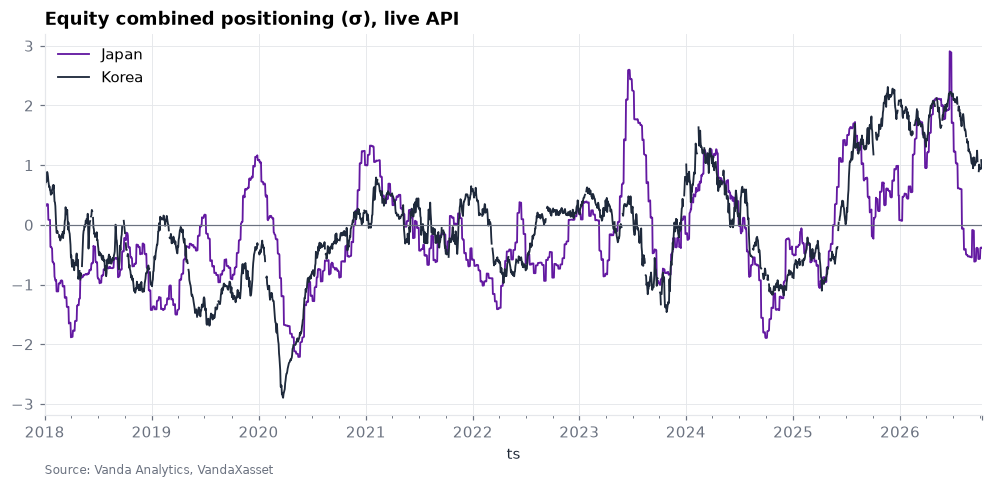

In [7]:
jp = qk.positioning_history(client, "JPEQCOMB", start="2018-01-01")
kr = qk.positioning_history(client, "KREQCOMB", start="2018-01-01")

ax = pd.concat({"Japan": jp.set_index("ts").value, "Korea": kr.set_index("ts").value}, axis=1).plot(lw=1.2, title="Equity combined positioning (σ), live API")
ax.axhline(0, color=qk.VANDA["sub"], lw=0.8)
qk.source_note(ax)
plt.show()

## 4. Python SDK: flow, addressed by slug

Search the flow catalogue for a label. Free-text search also matches the label's sector slices (`-COMS`, `-TECH`, ...),
so pick the exact label. Each entry lists every per-metric series under it, with its slug:

In [8]:
label = "KREQSTCKFORMIXMIXMIX"
hits = client.flow.list_catalog(q=label)
print("search returned:", [e["identity"]["series_label"] for e in hits["data"]])
entry = next(e for e in hits["data"] if e["identity"]["series_label"] == label)
print(entry["identity"]["name"], "|", entry["identity"]["series_label"])
variants = pd.DataFrame(entry["series"])[["metric", "unit", "frequency", "measure_class", "slug", "start_date"]]
variants

search returned: ['KREQSTCKFORMIXMIXMIX-COMS', 'KREQSTCKFORMIXMIXMIX-ENER', 'KREQSTCKFORMIXMIXMIX-STAP', 'KREQSTCKFORMIXMIXMIX-UTIL', 'KREQSTCKFORMIXMIXMIX-INDU', 'KREQSTCKFORMIXMIXMIX-HLTH', 'KREQSTCKFORMIXMIXMIX-RLST', 'KREQSTCKFORMIXMIXMIX-FINA', 'KREQSTCKFORMIXMIXMIX-DISC', 'KREQSTCKFORMIXMIXMIX', 'KREQSTCKFORMIXMIXMIX-TECH', 'KREQSTCKFORMIXMIXMIX-MATE']
Korea Foreign inv. Stocks | KREQSTCKFORMIXMIXMIX


,metric,unit,frequency,measure_class,slug,start_date
0,buy_value,USDmn,daily,flow,FLOW.KR.KREQ.V1:FOREIGNERS~TOTAL:BUY_VALUE:KRE...,2015-05-04
1,buy_volume,shares,daily,flow,FLOW.KR.KREQ.V1:FOREIGNERS~TOTAL:BUY_VOLUME:KR...,2015-05-04
2,net_value,USDmn,daily,flow,FLOW.KR.KREQ.V1:FOREIGNERS~TOTAL:NET_VALUE:KRE...,2015-05-04
3,net_volume,shares,daily,flow,FLOW.KR.KREQ.V1:FOREIGNERS~TOTAL:NET_VOLUME:KR...,2015-05-04
4,sell_value,USDmn,daily,flow,FLOW.KR.KREQ.V1:FOREIGNERS~TOTAL:SELL_VALUE:KR...,2015-05-04
5,sell_volume,shares,daily,flow,FLOW.KR.KREQ.V1:FOREIGNERS~TOTAL:SELL_VOLUME:K...,2015-05-04
6,total_value,USDmn,daily,flow,FLOW.KR.KREQ.V1:FOREIGNERS~TOTAL:TOTAL_VALUE:K...,2015-05-04
7,total_volume,shares,daily,flow,FLOW.KR.KREQ.V1:FOREIGNERS~TOTAL:TOTAL_VOLUME:...,2015-05-04


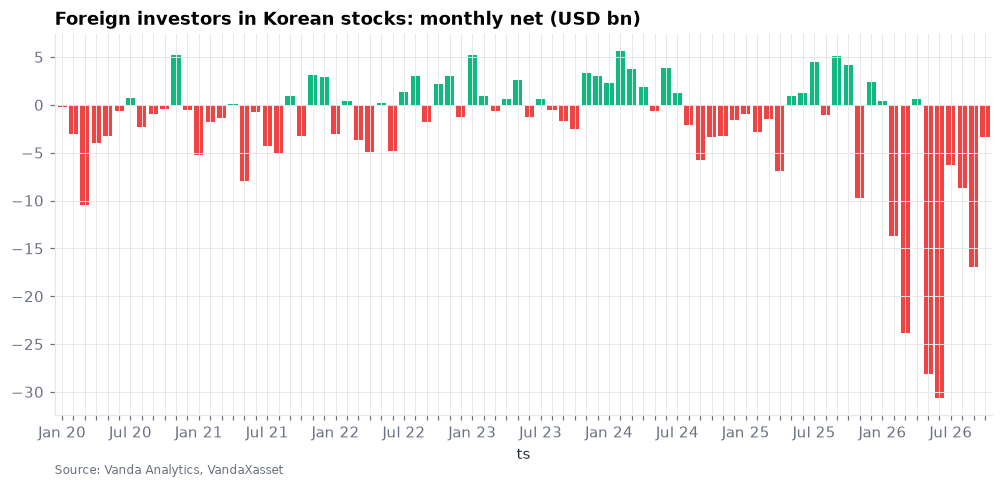

In [9]:
net_value_slug = variants.loc[variants.metric == "net_value", "slug"].iloc[0]

kr_foreign = qk.flow_history(client, net_value_slug, start="2020-01-01")
kr_monthly = kr_foreign.set_index("ts")["value"].resample("ME").sum() / 1_000

ax = kr_monthly.plot(kind="bar", color=[qk.VANDA["pos"] if v > 0 else qk.VANDA["neg"] for v in kr_monthly], width=0.8,
                     title="Foreign investors in Korean stocks: monthly net (USD bn)")
ax.set_xticklabels([d.strftime("%b %y") if d.month in (1, 7) else "" for d in kr_monthly.index], rotation=0)
qk.source_note(ax)
plt.show()

`get_latest` reports staleness alongside the value, which makes it a useful health check before a daily job:

In [10]:
fl = client.flow.get_latest(series_ids=["JPEQSTCKFORINSMIXMIX", "TWEQSTCKFORINSMIXMIX", "INEQSTCKFORINSMIXMIX"], metrics="net")
pd.DataFrame(fl["data"])[["series_label", "name", "metric", "ts", "value", "unit", "staleness_days"]]

,series_label,name,metric,ts,value,unit,staleness_days
0,JPEQSTCKFORINSMIXMIX,Japan Foreign Institutional Equity — Net,net,2026-10-02T00:00:00Z,6055.820773,USDmn,10
1,TWEQSTCKFORINSMIXMIX,Taiwan Foreign Institutional Equity — Net,net,2026-10-08T00:00:00Z,-2055.360000,USDmn,4
2,INEQSTCKFORINSMIXMIX,India Foreign Institutional Equities — Net,net,2026-10-08T00:00:00Z,-1337.470000,USDmn,4


## 5. Server-side transformations

Both services can transform a **single series** before returning it:

| Parameter | Values |
|---|---|
| `transformation` + `window` | `rolling_sum` or `moving_avg` over `5, 20, 30, 60, 90, 120, 252` observations |
| `normalisation` + `normalisation_period` | `zscore` or `percentile_rank` over `3m, 6m, 1y, 2y, 5y, Expanding, All` |

The raw series always stays under `data`. The transformed result arrives under `transformation`. If the transformation
fails or is skipped (for example because several series were requested), `transformation.status` says so and `data` still
holds the raw rows. **Check the status rather than assuming.** Transformed results cover the series' full history, so
trim them to the window you need.

In [11]:
resp = client.flow.get_timeseries(
    series_ids=net_value_slug, start_date="2022-01-01", order="asc", records_per_page=5000,
    transformation="rolling_sum", window="20", normalisation="zscore", normalisation_period="2y",
)
print("status:", (resp.get("transformation") or {}).get("status"))
pd.DataFrame((resp.get("transformation") or {}).get("results", {}).get("data", [])).tail()

status: success


,id,ts,net_value,net_value_rolling_sum,net_value_zscore,net_value_rolling_sum_zscore
2540,default,2026-09-30T00:00:00Z,-1577.51,-16918.04,-0.778349,-0.690555
2541,default,2026-10-01T00:00:00Z,262.48,-16184.52,0.560603,-0.619733
2542,default,2026-10-02T00:00:00Z,-208.21,-15020.29,0.222550,-0.510795
2543,default,2026-10-06T00:00:00Z,-1219.81,-16192.16,-0.512038,-0.609181
2544,default,2026-10-07T00:00:00Z,-2154.51,-18915.44,-1.186848,-0.845418


A 1-year percentile rank of US Treasury 10Y positioning, computed server-side:

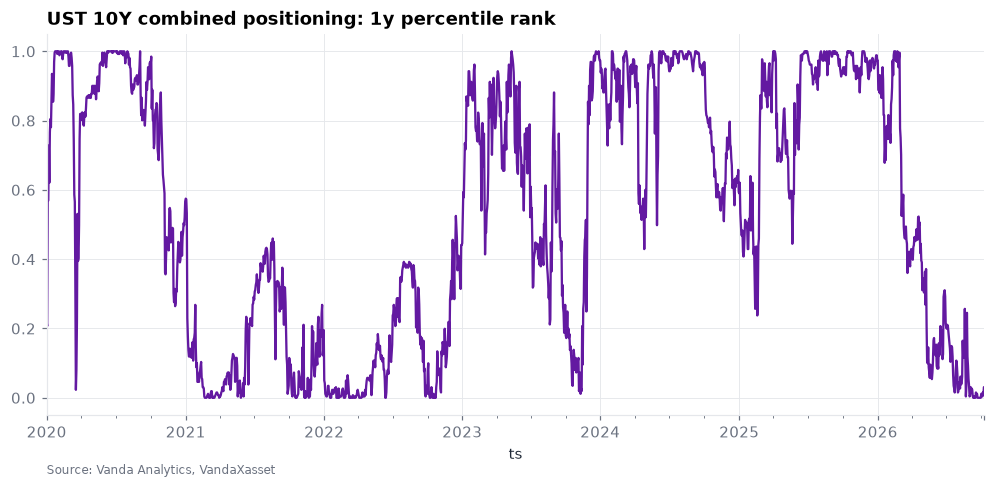

In [12]:
ust10_pct = qk.positioning_history(client, "USFICOMB-10YR", start="2020-01-01", normalisation="percentile_rank", normalisation_period="1y")
ax = ust10_pct.set_index("ts")["value"].plot(title="UST 10Y combined positioning: 1y percentile rank", color=qk.VANDA["purple"])
qk.source_note(ax)
plt.show()

## 6. Restated vs point-in-time via the API

`revision="point_in_time"` returns each value **as it was first published**, which is what you would have known on the
day. Use it for backtests (see notebook 04). Values before September 2026 are reconstructed; later values are captured live.

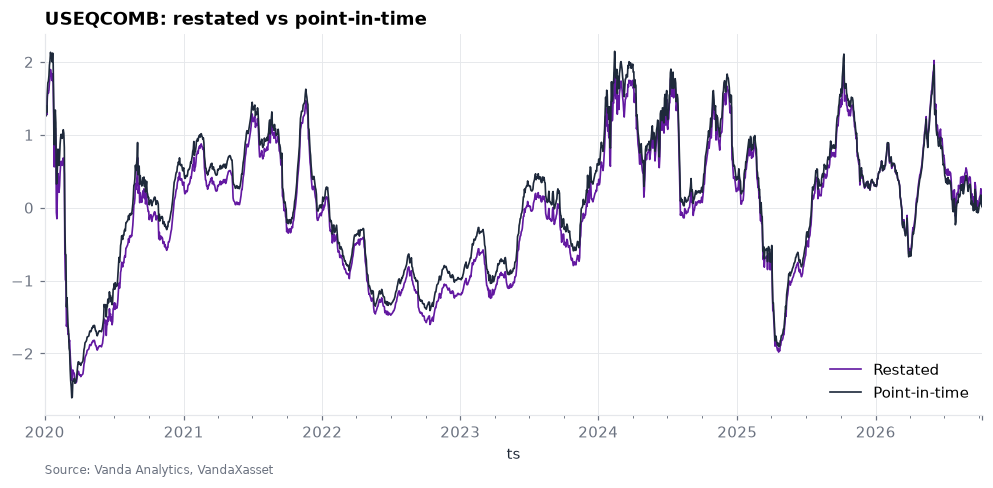

In [13]:
rest = qk.positioning_history(client, "USEQCOMB", start="2020-01-01", revision="restated")
pit = qk.positioning_history(client, "USEQCOMB", start="2020-01-01", revision="point_in_time")
ax = pd.concat({"Restated": rest.set_index("ts").value, "Point-in-time": pit.set_index("ts").value}, axis=1).plot(lw=1.1, title="USEQCOMB: restated vs point-in-time")
qk.source_note(ax)
plt.show()

## 7. The systematic forecast cube

For systematic strategies (CTA, risk parity, vol targeting, dealer gamma) the flow service publishes a **cube** for each
run date. It projects how exposure would evolve over the next *N* market days under a grid of price scenarios. Read the
axes first: the scenario axis is named per component (`zscore` for cta/rp/vt, `ret` for gamma).

In [14]:
runs = client.flow.get_forecast_runs(series_ids="USEQFUTUES1MIXINSSPECTA")
axes = runs["data"][0]
print("components:", axes["components"], "| scenario axis:", axes["scenario_key"])
print("latest run:", axes["run_dates"][-1], "| horizons:", axes["horizons"][:5], "...", axes["horizons"][-1])
print("scenarios:", axes["scenarios"][:6], "...")

components: ['cta'] | scenario axis: zscore
latest run: 2026-10-09T00:00:00Z | horizons: [0, 1, 2, 3, 4] ... 15
scenarios: ['-3.0', '-2.9', '-2.8', '-2.7', '-2.6', '-2.5'] ...


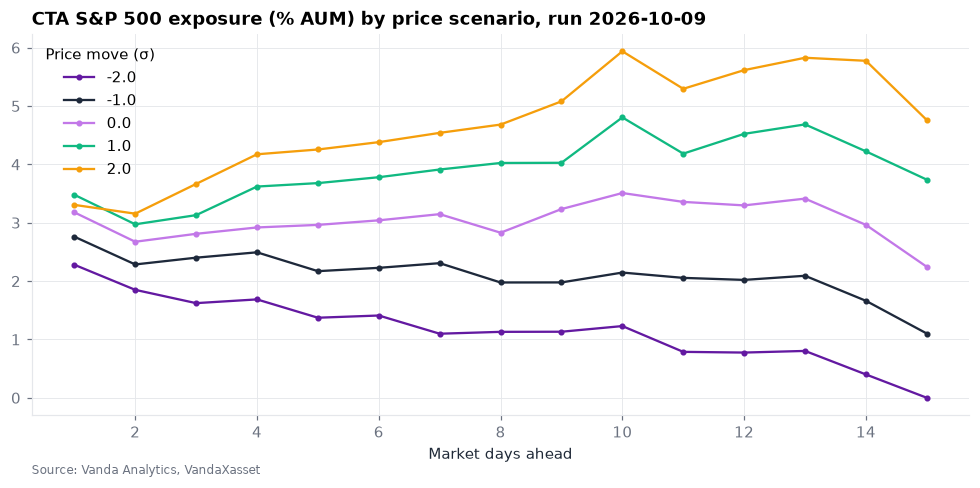

In [15]:
cube = client.flow.get_forecast(
    series_ids="USEQFUTUES1MIXINSSPECTA", components="cta", metrics="exposure_as_perc_aum",
    scenarios=["-2.0", "-1.0", "0.0", "1.0", "2.0"], horizons=list(range(1, 16)),
)
proj = pd.DataFrame([
    {"scenario": g["scenario"], "horizon": g["horizon"], "value": g["metrics"]["exposure_as_perc_aum"]["value"] * 100}
    for g in cube["data"]
]).pivot(index="horizon", columns="scenario", values="value")
proj = proj[sorted(proj.columns, key=float)]

ax = proj.plot(marker="o", ms=3, title=f"CTA S&P 500 exposure (% AUM) by price scenario, run {cube['run_date'][:10]}")
ax.set_xlabel("Market days ahead")
ax.legend(title="Price move (σ)")
qk.source_note(ax)
plt.show()

## 8. Bulk export to file

The export endpoints stream CSV or JSON, optionally gzipped. Full-history exports need Data Licence entitlement;
without it they are refused with `RateLimitError`.

In [16]:
out = Path("output")
out.mkdir(exist_ok=True)
client.positioning.export_timeseries(series_ids="USEQCOMB", output_path=str(out / "USEQCOMB.csv"), start_date="2024-01-01")
pd.read_csv(out / "USEQCOMB.csv").tail()

,legacy_series_id,metric,name,revision,series_id,series_label,ts,unit,value,version
720,USEQCOMB,combined_positioning,US Equity,restated,3982797578764688117,USEQCOMB,2026-10-05T00:00:00+00:00,zscore,0.171049,V1
721,USEQCOMB,combined_positioning,US Equity,restated,3982797578764688117,USEQCOMB,2026-10-06T00:00:00+00:00,zscore,0.260090,V1
722,USEQCOMB,combined_positioning,US Equity,restated,3982797578764688117,USEQCOMB,2026-10-07T00:00:00+00:00,zscore,0.124843,V1
723,USEQCOMB,combined_positioning,US Equity,restated,3982797578764688117,USEQCOMB,2026-10-08T00:00:00+00:00,zscore,0.093358,V1
724,USEQCOMB,combined_positioning,US Equity,restated,3982797578764688117,USEQCOMB,2026-10-09T00:00:00+00:00,zscore,0.198629,V1


---
**Next:** `02 - Catalogue Tour & Series Taxonomy`.

API reference: [docs.vanda-analytics.com](https://docs.vanda-analytics.com/) · SDK: [`vanda-api` on PyPI](https://pypi.org/project/vanda-api/)